# Expliquer un détecteur d'intrusion — UNSW-NB15
**Projet 1 (Interprétabilité) — Module Machine Learning pour la cybersécurité**

Question centrale : le modèle apprend-il des *comportements d'attaque* ou des *artefacts de collecte* ?

**Plan** : 0. Setup · 1. Données & nettoyage · 2. Découpage · 3. Modèles (socle commun) · 4. Évaluation · 5. Trois mesures d'importance · 6. Cinq alertes expliquées · 7. Audit de plausibilité · 8. Ablation · 9. Stabilité · 10. Conclusion & limites

**Données** (non versionnées) : télécharger `UNSW_NB15_training-set.csv` et `UNSW_NB15_testing-set.csv` (UNSW Canberra / Kaggle), les placer dans `data/`.

## 0. Setup et reproductibilité

In [1]:
import warnings, time, platform, random
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sklearn, xgboost, shap
from scipy.stats import spearmanr, randint, uniform
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.base import clone
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (confusion_matrix, classification_report, precision_recall_curve,
                             average_precision_score, roc_auc_score, f1_score, PrecisionRecallDisplay)
from xgboost import XGBClassifier

SEED = 42
random.seed(SEED); np.random.seed(SEED)
print("python", platform.python_version(), "| sklearn", sklearn.__version__,
      "| xgboost", xgboost.__version__, "| shap", shap.__version__, "| pandas", pd.__version__)

python 3.12.10 | sklearn 1.9.1 | xgboost 3.4.1 | shap 0.54.1 | pandas 3.1.1


## 1. Données et nettoyage

In [2]:
DATA = "data/"
raw_tr = pd.read_csv(DATA + "UNSW_NB15_training-set.csv")
raw_te = pd.read_csv(DATA + "UNSW_NB15_testing-set.csv")
print(raw_tr.shape, raw_te.shape)
raw_tr.head()

(82332, 45) (175341, 45)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.000011,udp,-,INT,2,0,496,0,90909.0902,...,1,2,0,0,0,1,2,0,Normal,0
1,2,0.000008,udp,-,INT,2,0,1762,0,125000.0003,...,1,2,0,0,0,1,2,0,Normal,0
2,3,0.000005,udp,-,INT,2,0,1068,0,200000.0051,...,1,3,0,0,0,1,3,0,Normal,0
3,4,0.000006,udp,-,INT,2,0,900,0,166666.6608,...,1,3,0,0,0,2,3,0,Normal,0
4,5,0.000010,udp,-,INT,2,0,2126,0,100000.0025,...,1,3,0,0,0,2,3,0,Normal,0


**À décrire dans le rapport** : origine (UNSW Canberra, ACCS), nature des variables (durées, paquets, octets, états, protocole, service…), classes (`label` 0/1 et `attack_cat` : 9 familles), proportion d'attaques (voir cellule suivante).

In [3]:
for name, d in [("train officiel", raw_tr), ("test officiel", raw_te)]:
    print(name, "| part d'attaques :", round(d["label"].mean(), 3))
print(raw_tr["attack_cat"].value_counts())

train officiel | part d'attaques : 0.551
test officiel | part d'attaques : 0.681
attack_cat
Normal            37000
Generic           18871
Exploits          11132
Fuzzers            6062
DoS                4089
Reconnaissance     3496
Analysis            677
Backdoor            583
Shellcode           378
Worms                44
Name: count, dtype: int64


In [4]:
def clean(df):
    df = df.copy()
    n0 = len(df)
    df = df.drop(columns=[c for c in ["id"] if c in df.columns])      # simple index, pas une variable
    df = df.replace([np.inf, -np.inf], np.nan)
    print("valeurs manquantes :", int(df.isna().sum().sum()))
    df = df.dropna()
    df = df.drop_duplicates()
    print(f"lignes : {n0} -> {len(df)} (doublons/NaN retirés : {n0-len(df)})")
    return df

tr = clean(raw_tr); te = clean(raw_te)
te_official = te.copy()  # partition officielle nettoyée, avant retrait des recouvrements train/test

# doublons ENTRE train et test (fuite directe) : on les retire du test
feat_cols = [c for c in tr.columns if c not in ("label", "attack_cat")]
key = lambda d: d[feat_cols].astype(str).agg("|".join, axis=1)
dup_cross = key(te).isin(set(key(tr)))
print("doublons train/test :", int(dup_cross.sum()), f"({dup_cross.mean():.1%} du test)")
te = te[~dup_cross].reset_index(drop=True)
tr = tr.reset_index(drop=True)

valeurs manquantes : 0


lignes : 82332 -> 55945 (doublons/NaN retirés : 26387)


valeurs manquantes : 0


lignes : 175341 -> 107740 (doublons/NaN retirés : 67601)


doublons train/test : 1722 (1.6% du test)


**Justifier chaque choix** : suppression des doublons (sinon fuite train→test), `inf`/NaN retirés (peu nombreux, ou à imputer sur le train seul), `id` retiré (index).
**Références** : Moustafa & Slay (2015), description du jeu UNSW-NB15 ; Moustafa & Slay (2016), analyse statistique et comparaison avec KDD99 ; Ring et al. (2019), revue critique des jeux de données NIDS. Références complètes en fin de notebook.

## 2. Découpage entraînement / validation / test
On conserve le découpage officiel pour le test final, jamais utilisé pour choisir le modèle, le seuil ou les variables à expliquer. Le train officiel est séparé en train/validation stratifiés. Les comparaisons exploratoires, importances, SHAP, exemples et ablation utilisent uniquement la validation.
**Limites** : découpage non temporel ; des flux d'une même session peuvent être répartis des deux côtés. Le test officiel a une composition différente : son évaluation finale est accompagnée d'un diagnostic descriptif du décalage, sans réajustement après consultation du test.

In [5]:
y_all = tr["label"]
X_all = tr.drop(columns=["label", "attack_cat"])
X_train, X_val, y_train, y_val = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED)
X_test, y_test = te.drop(columns=["label", "attack_cat"]), te["label"]
X_test_official = te_official.drop(columns=["label", "attack_cat"])
y_test_official = te_official["label"]
attack_cat_val = tr.loc[X_val.index, "attack_cat"].reset_index(drop=True)

cat_cols = X_train.select_dtypes(include="object").columns.tolist()
num_cols = [c for c in X_train.columns if c not in cat_cols]
print("catégorielles :", cat_cols, "| numériques :", len(num_cols))
print({k: (len(v), round(float(w.mean()), 3)) for k, (v, w) in
       {"train": (X_train, y_train), "val": (X_val, y_val)}.items()})

catégorielles : ['proto', 'service', 'state'] | numériques : 39
{'train': (44756, 0.389), 'val': (11189, 0.389)}


## 3. Modèles (socle commun) — preprocessing et modèles ajustés dans chaque fold

In [6]:
# Encodage ordinal (ajusté sur le train) pour les arbres ; one-hot + standardisation pour la régression logistique
ord_enc = ColumnTransformer(
    [("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols)],
    remainder="passthrough", verbose_feature_names_out=False).set_output(transform="pandas")
lr_pre = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01), cat_cols),
    ("num", StandardScaler(), num_cols)])
baseline = Pipeline([("pre", lr_pre), ("clf", LogisticRegression(max_iter=1000, class_weight="balanced",
                                                                 random_state=SEED))])
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

t0 = time.time(); baseline.fit(X_train, y_train); t_lr = time.time() - t0

rf_pipeline = Pipeline([
    ("pre", clone(ord_enc)),
    ("model", RandomForestClassifier(n_jobs=-1, class_weight="balanced", random_state=SEED)),
])
rf_search = RandomizedSearchCV(
    rf_pipeline,
    {"model__n_estimators": randint(100, 300), "model__max_depth": [10, 20, None],
     "model__min_samples_leaf": randint(1, 10), "model__max_features": ["sqrt", 0.3]},
    n_iter=8, scoring="average_precision", cv=cv, random_state=SEED, n_jobs=1)
t0 = time.time(); rf_search.fit(X_train, y_train); t_rf = time.time() - t0
rf = rf_search.best_estimator_.named_steps["model"]
ord_enc = rf_search.best_estimator_.named_steps["pre"]
Xtr_t = ord_enc.transform(X_train)
Xva_t = ord_enc.transform(X_val)
Xte_t = ord_enc.transform(X_test)
Xte_official_t = ord_enc.transform(X_test_official)
feature_names = Xtr_t.columns.tolist()

spw = float((y_train == 0).sum() / (y_train == 1).sum())
xgb_pipeline = Pipeline([
    ("pre", clone(ord_enc)),
    ("model", XGBClassifier(tree_method="hist", n_jobs=-1, random_state=SEED, eval_metric="aucpr")),
])
xgb_search = RandomizedSearchCV(
    xgb_pipeline,
    {"model__n_estimators": randint(150, 500), "model__max_depth": randint(3, 9),
     "model__learning_rate": uniform(0.03, 0.2), "model__subsample": uniform(0.7, 0.3),
     "model__colsample_bytree": uniform(0.6, 0.4), "model__scale_pos_weight": [1, spw]},
    n_iter=10, scoring="average_precision", cv=cv, random_state=SEED, n_jobs=1)
t0 = time.time(); xgb_search.fit(X_train, y_train); t_xgb = time.time() - t0
xgb = xgb_search.best_estimator_.named_steps["model"]
print("RF :", rf_search.best_params_); print("XGB:", xgb_search.best_params_)

RF : {'model__max_depth': 20, 'model__max_features': 0.3, 'model__min_samples_leaf': 2, 'model__n_estimators': 291}
XGB: {'model__colsample_bytree': np.float64(0.6362425738131283), 'model__learning_rate': np.float64(0.15367720186661746), 'model__max_depth': 6, 'model__n_estimators': 204, 'model__scale_pos_weight': 1.573515036513139, 'model__subsample': np.float64(0.8777243706586126)}


## 4. Évaluation
On compare d'abord sur la **validation**. Le **test** n'est utilisé qu'une seule fois, pour les résultats finaux.

In [7]:
def report(name, y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    print(f"=== {name} ===")
    print(confusion_matrix(y_true, pred))
    print(classification_report(y_true, pred, digits=3, target_names=["normal", "attaque"]))
    return {"modèle": name, "PR-AUC": average_precision_score(y_true, proba),
            "ROC-AUC": roc_auc_score(y_true, proba), "F1 attaque": f1_score(y_true, pred)}

def infer_time(model, X, n=5):
    t0 = time.time()
    for _ in range(n): model.predict_proba(X)
    return (time.time() - t0) / n / len(X) * 1e6    # µs / flux

val_rows = [report("Baseline LR", y_val, baseline.predict_proba(X_val)[:, 1]),
            report("Random Forest", y_val, rf.predict_proba(Xva_t)[:, 1]),
            report("XGBoost", y_val, xgb.predict_proba(Xva_t)[:, 1])]
val_tab = pd.DataFrame(val_rows)
val_tab["train (s)"] = [t_lr, t_rf, t_xgb]
val_tab["inférence (µs/flux)"] = [infer_time(baseline, X_val), infer_time(rf, Xva_t), infer_time(xgb, Xva_t)]
val_tab.round(4)

=== Baseline LR ===
[[5834 1007]
 [ 428 3920]]
              precision    recall  f1-score   support

      normal      0.932     0.853     0.890      6841
     attaque      0.796     0.902     0.845      4348

    accuracy                          0.872     11189
   macro avg      0.864     0.877     0.868     11189
weighted avg      0.879     0.872     0.873     11189

=== Random Forest ===
[[6669  172]
 [ 184 4164]]
              precision    recall  f1-score   support

      normal      0.973     0.975     0.974      6841
     attaque      0.960     0.958     0.959      4348

    accuracy                          0.968     11189
   macro avg      0.967     0.966     0.967     11189
weighted avg      0.968     0.968     0.968     11189



=== XGBoost ===


[[6700  141]
 [ 160 4188]]
              precision    recall  f1-score   support

      normal      0.977     0.979     0.978      6841
     attaque      0.967     0.963     0.965      4348

    accuracy                          0.973     11189
   macro avg      0.972     0.971     0.972     11189
weighted avg      0.973     0.973     0.973     11189



,modèle,PR-AUC,ROC-AUC,F1 attaque,train (s),inférence (µs/flux)
0,Baseline LR,0.9446,0.9589,0.8453,1.6505,2.3151
1,Random Forest,0.9924,0.9946,0.9590,72.0006,8.4871
2,XGBoost,0.9941,0.9958,0.9653,40.2803,1.4902


**Discussion à rédiger** (coût des erreurs) : un faux négatif = attaque non détectée (compromission, exfiltration) ; un faux positif = alerte inutile pour l'analyste (fatigue d'alerte, temps perdu). Argumenter le seuil de décision retenu et son lien avec la charge d'alertes. La PR-AUC se lit par rapport à la proportion d'attaques (référence d'un modèle aléatoire).

### Comparaison exploratoire sur validation
Les choix et comparaisons de modèles se font sur la validation. Le test officiel reste réservé au bloc final, après toutes les analyses et l'ablation.

In [8]:
val_rows = [report("Baseline LR", y_val, baseline.predict_proba(X_val)[:, 1]),
            report("Random Forest", y_val, rf.predict_proba(Xva_t)[:, 1]),
            report("XGBoost", y_val, xgb.predict_proba(Xva_t)[:, 1])]
val_tab = pd.DataFrame(val_rows).round(4)
val_tab

=== Baseline LR ===
[[5834 1007]
 [ 428 3920]]
              precision    recall  f1-score   support

      normal      0.932     0.853     0.890      6841
     attaque      0.796     0.902     0.845      4348

    accuracy                          0.872     11189
   macro avg      0.864     0.877     0.868     11189
weighted avg      0.879     0.872     0.873     11189

=== Random Forest ===
[[6669  172]
 [ 184 4164]]
              precision    recall  f1-score   support

      normal      0.973     0.975     0.974      6841
     attaque      0.960     0.958     0.959      4348

    accuracy                          0.968     11189
   macro avg      0.967     0.966     0.967     11189
weighted avg      0.968     0.968     0.968     11189

=== XGBoost ===
[[6700  141]
 [ 160 4188]]
              precision    recall  f1-score   support

      normal      0.977     0.979     0.978      6841
     attaque      0.967     0.963     0.965      4348

    accuracy                          0.973

,modèle,PR-AUC,ROC-AUC,F1 attaque
0,Baseline LR,0.9446,0.9589,0.8453
1,Random Forest,0.9924,0.9946,0.9590
2,XGBoost,0.9941,0.9958,0.9653


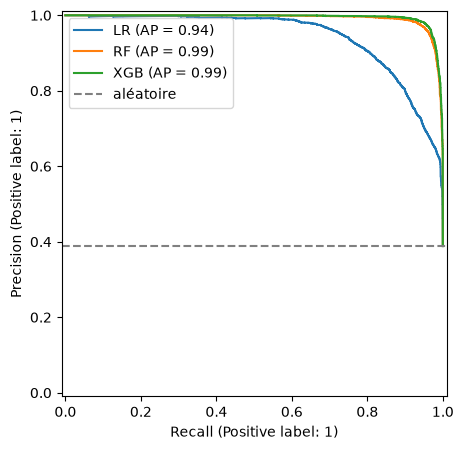

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, p in [("LR", baseline.predict_proba(X_val)[:, 1]), ("RF", rf.predict_proba(Xva_t)[:, 1]),
                ("XGB", xgb.predict_proba(Xva_t)[:, 1])]:
    PrecisionRecallDisplay.from_predictions(y_val, p, name=name, ax=ax)
ax.axhline(y_val.mean(), ls="--", c="gray", label="aléatoire"); ax.legend()
plt.savefig("figures/pr_curves_validation.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Trois mesures d'importance (modèle expliqué : Random Forest)
Importance interne (MDI) · importance par permutation sur la validation (baisse de PR-AUC) · moyenne des |SHAP| sur la validation.
Rappel des pièges : variables corrélées (importance répartie ou masquée), importances à ne pas lire comme des effets isolés.

In [10]:
imp_mdi = pd.Series(rf.feature_importances_, index=feature_names, name="MDI")

rng = np.random.RandomState(SEED)
idx_perm = rng.choice(len(Xva_t), size=min(10000, len(Xva_t)), replace=False)
perm = permutation_importance(rf, Xva_t.iloc[idx_perm], y_val.iloc[idx_perm],
                              scoring="average_precision", n_repeats=5, random_state=SEED, n_jobs=1)
imp_perm = pd.Series(perm.importances_mean, index=feature_names, name="Permutation")

# SHAP : échantillon de 2000 flux au plus, tiré dans la validation
idx_shap = rng.choice(len(Xva_t), size=min(2000, len(Xva_t)), replace=False)
Xs = Xva_t.iloc[idx_shap]
explainer = shap.TreeExplainer(rf)
sv = explainer.shap_values(Xs)
sv = sv[1] if isinstance(sv, list) else (sv[..., 1] if sv.ndim == 3 else sv)   # classe « attaque »
imp_shap = pd.Series(np.abs(sv).mean(axis=0), index=feature_names, name="|SHAP|")

imp = pd.concat([imp_mdi, imp_perm, imp_shap], axis=1)
ranks = imp.rank(ascending=False)
imp_tab = imp.join(ranks.add_suffix(" (rang)")).sort_values("|SHAP|", ascending=False)
imp_tab.head(15).round(4)

,MDI,Permutation,|SHAP|,MDI (rang),Permutation (rang),|SHAP| (rang)
sttl,0.1464,0.1254,0.1474,1.0,1.0,1.0
ct_dst_src_ltm,0.1432,0.0911,0.0937,2.0,2.0,2.0
ct_state_ttl,0.1222,0.0087,0.0851,3.0,4.0,3.0
ct_srv_dst,0.0645,0.0097,0.0337,4.0,3.0,4.0
dbytes,0.0283,0.0061,0.0238,10.0,6.0,5.0
sbytes,0.0521,0.0081,0.0232,5.0,5.0,6.0
ct_dst_sport_ltm,0.0389,0.0032,0.0206,6.0,10.0,7.0
dttl,0.0088,0.0036,0.0203,25.0,8.0,8.0
smean,0.0377,0.0060,0.0201,7.0,7.0,9.0
synack,0.0283,0.0022,0.0172,9.0,16.0,10.0


Corrélation de Spearman entre classements :
              MDI  Permutation  |SHAP|
MDI          1.00         0.88    0.93
Permutation  0.88         1.00    0.96
|SHAP|       0.93         0.96    1.00


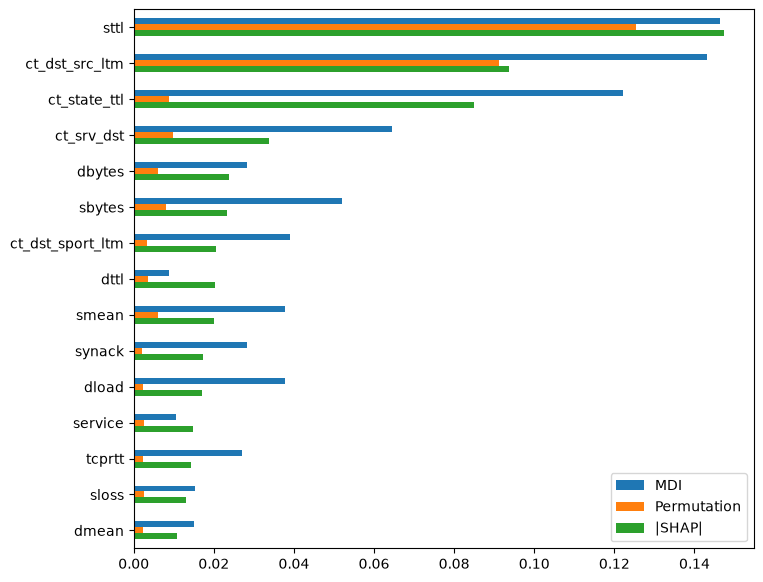

In [11]:
print("Corrélation de Spearman entre classements :")
print(ranks.corr(method="spearman").round(2))
imp_tab.head(15)[["MDI", "Permutation", "|SHAP|"]].plot.barh(figsize=(8, 7)); plt.gca().invert_yaxis()
plt.savefig("figures/feature_importance_validation.png", dpi=160, bbox_inches="tight")
plt.show()

**À discuter** : pourquoi les classements diffèrent (MDI biaisé vers variables à forte cardinalité, permutation et corrélations, SHAP et attribution partagée).

## 6. Cinq alertes expliquées (2 VP, 2 FP, 1 FN)
Pour chacune : valeurs clés, contributions SHAP, puis texte d'analyste.


##### VP | index validation 5363 | proba=0.998 | famille=Exploits


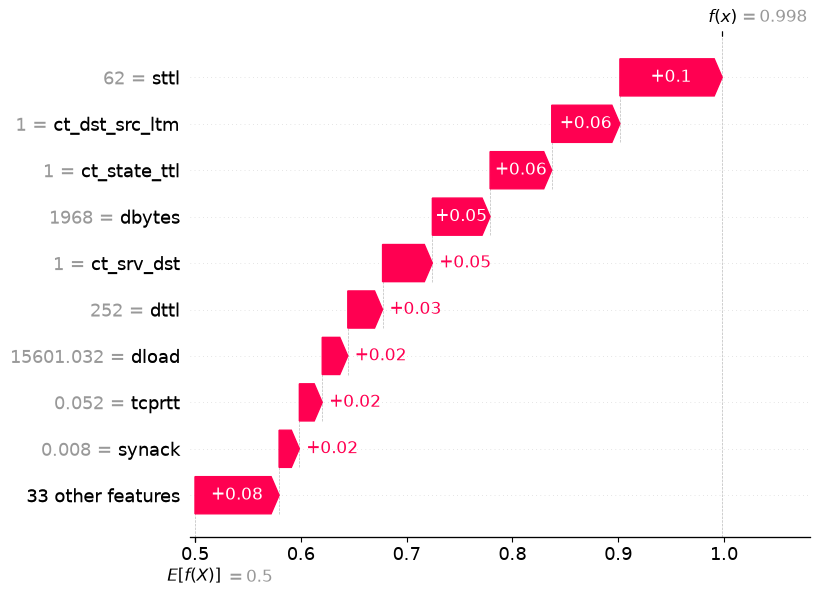


##### VP | index validation 9815 | proba=1.000 | famille=Generic


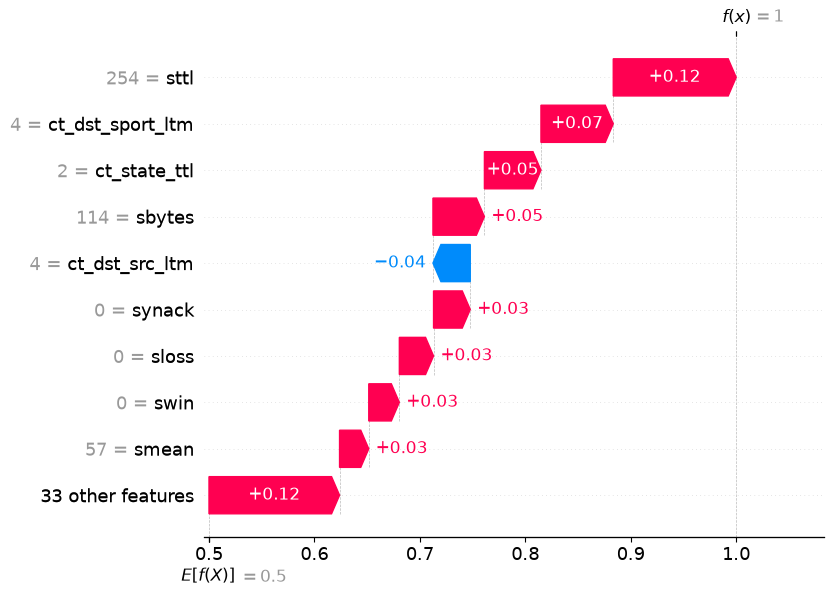


##### FP | index validation 4712 | proba=0.627 | famille=Normal


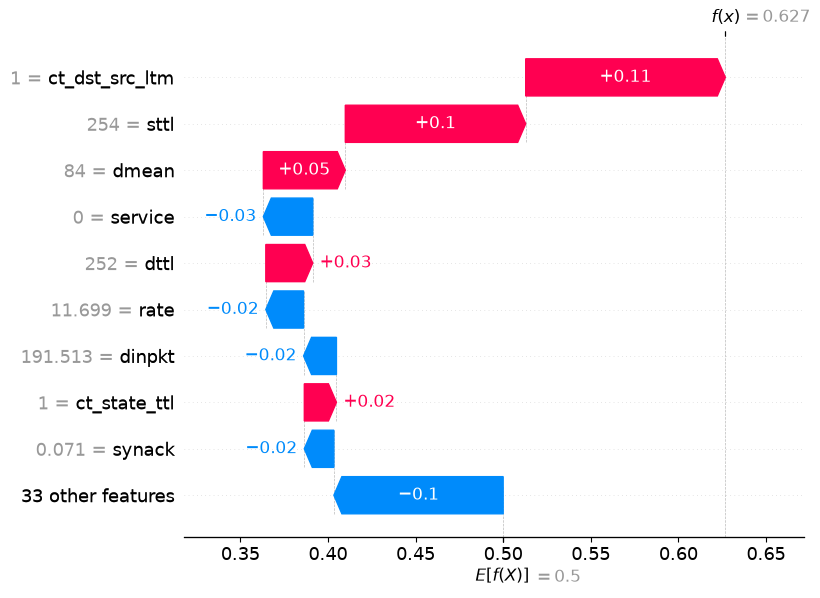


##### FP | index validation 9006 | proba=0.606 | famille=Normal


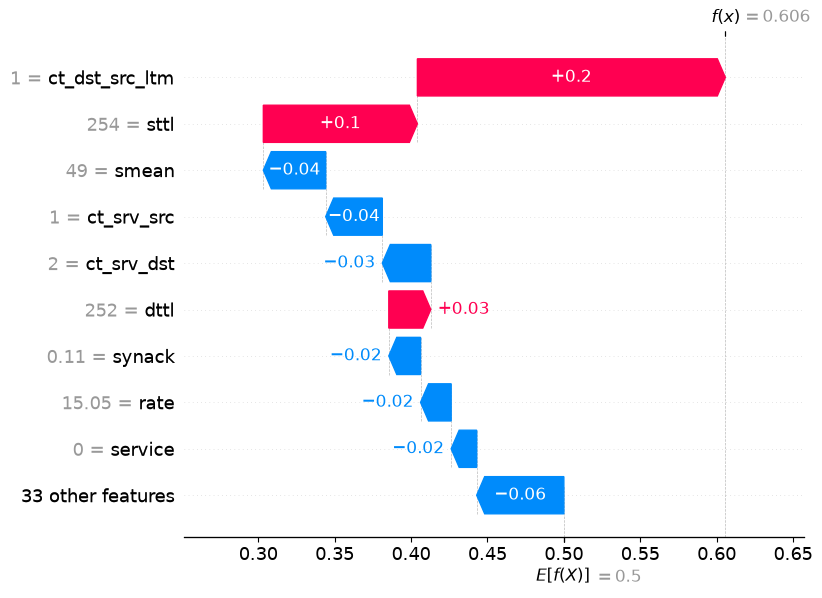


##### FN | index validation 1170 | proba=0.389 | famille=Fuzzers


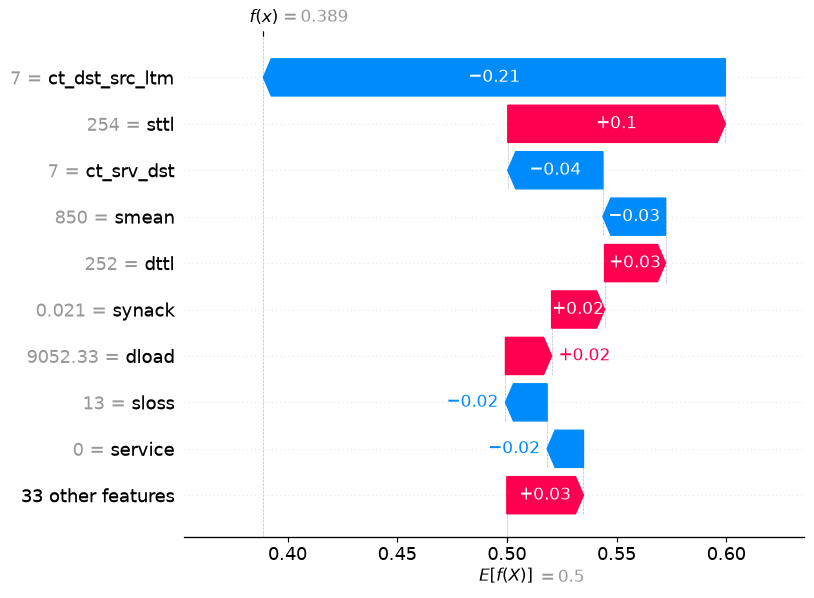

In [12]:
proba_val = rf.predict_proba(Xva_t)[:, 1]
pred_val = (proba_val >= 0.5).astype(int)
yv = y_val.values
pick = lambda mask, k: list(np.random.RandomState(SEED).choice(np.where(mask)[0], size=k, replace=False))
cases = {"VP": pick((pred_val == 1) & (yv == 1), 2),
         "FP": pick((pred_val == 1) & (yv == 0), 2),
         "FN": pick((pred_val == 0) & (yv == 1), 1)}
base = explainer.expected_value
base = base[1] if np.ndim(base) else base

for kind, ids in cases.items():
    for i in ids:
        s = explainer.shap_values(Xva_t.iloc[[i]])
        s = s[1][0] if isinstance(s, list) else (s[0, :, 1] if s.ndim == 3 else s[0])
        print(f"\n##### {kind} | index validation {i} | proba={proba_val[i]:.3f} | famille={attack_cat_val[i]}")
        shap.plots.waterfall(shap.Explanation(values=s, base_values=base,
                             data=Xva_t.iloc[i].values, feature_names=feature_names), max_display=10)

**Texte d'analyste à rédiger pour chaque alerte** (modèle) :
> *Alerte n°X (VP/FP/FN).* Le flux [protocole/service/état] présente [variables dominantes + valeurs]. Le modèle le juge [malveillant/normal] surtout à cause de [contributions SHAP]. Du point de vue réseau, c'est [cohérent / suspect] car [...]. Action recommandée : [...].

## 7. Audit de plausibilité des 10 variables les plus importantes
Compléter le tableau (une ligne par variable) :

| Variable | Rôle réseau | Plausible comme signal d'attaque ? | Artefact possible ? | Verdict |
|---|---|---|---|---|
| … | … | … | … | … |

Variables à regarder de près : `sttl`, `dttl`, `ct_state_ttl`, `sbytes`/`dbytes`, `state`, `proto`, `service`, compteurs `ct_*`. Un TTL ou un compteur dépendant de la façon dont le trafic a été généré peut être un **artefact de collecte** plutôt qu'un comportement d'attaque.

In [13]:
top10 = imp_tab.head(10).index.tolist()
print(top10)

['sttl', 'ct_dst_src_ltm', 'ct_state_ttl', 'ct_srv_dst', 'dbytes', 'sbytes', 'ct_dst_sport_ltm', 'dttl', 'smean', 'synack']


## 8. Ablation : ré-entraînement sans les variables suspectes

In [14]:
SUSPECT = ["sttl", "ct_state_ttl"]  # TTL/état à tester après l'audit de plausibilité

keep = [c for c in feature_names if c not in SUSPECT]
rf_abl = RandomForestClassifier(**{k: v for k, v in rf.get_params().items()}).fit(Xtr_t[keep], y_train)
p_full = rf.predict_proba(Xva_t)[:, 1]
p_abl = rf_abl.predict_proba(Xva_t[keep])[:, 1]
pd.DataFrame([
    {"modèle": "complet", "PR-AUC": average_precision_score(y_val, p_full), "F1": f1_score(y_val, p_full >= .5)},
    {"modèle": f"sans {SUSPECT}", "PR-AUC": average_precision_score(y_val, p_abl), "F1": f1_score(y_val, p_abl >= .5)},
]).round(4)

,modèle,PR-AUC,F1
0,complet,0.9924,0.9590
1,"sans ['sttl', 'ct_state_ttl']",0.9919,0.9583


**Interprétation** : chute forte → le modèle initial s'appuyait sur ces variables (robuste ? artefact ?). Chute faible → robuste. Rapprocher du résultat de l'audit.

## 9. Stabilité des explications
On entraîne chaque modèle sur 80 % du sous-ensemble d'entraînement (graines stratifiées différentes) et on calcule les importances SHAP sur le même X_val indépendant. Le top 10 est comparé entre graines.

In [15]:
def shap_top(seed, k=10):
    Xa, _, ya, _ = train_test_split(X_train, y_train, train_size=0.8, stratify=y_train, random_state=seed)
    Xa_t = ord_enc.transform(Xa)
    m = RandomForestClassifier(**{**rf.get_params(), "random_state": seed}).fit(Xa_t, ya)
    ids = np.random.RandomState(seed).choice(len(Xva_t), size=min(1000, len(Xva_t)), replace=False)
    s = shap.TreeExplainer(m).shap_values(Xva_t.iloc[ids])
    s = s[1] if isinstance(s, list) else (s[..., 1] if s.ndim == 3 else s)
    return pd.Series(np.abs(s).mean(0), index=feature_names).sort_values(ascending=False).head(k).index.tolist()

tops = {sd: shap_top(sd) for sd in [1, 2, 3]}
sets = [set(v) for v in tops.values()]
jacc = np.mean([len(a & b) / len(a | b) for i, a in enumerate(sets) for b in sets[i+1:]])
print("Jaccard moyen du top-10 :", round(jacc, 2))
pd.DataFrame(tops)

Jaccard moyen du top-10 : 1.0


,1,2,3
0,sttl,sttl,sttl
1,ct_dst_src_ltm,ct_dst_src_ltm,ct_dst_src_ltm
2,ct_state_ttl,ct_state_ttl,ct_state_ttl
3,ct_srv_dst,ct_srv_dst,ct_srv_dst
4,dbytes,dttl,dttl
5,dttl,dbytes,dbytes
6,sbytes,smean,ct_dst_sport_ltm
7,smean,sbytes,smean
8,ct_dst_sport_ltm,dload,sbytes
9,dload,ct_dst_sport_ltm,dload


## 10. Conclusion et limites
**Résultat principal** : sur la validation, XGBoost atteint un F1 attaque de 0,9653 ; sur le test officiel, le F1 tombe à 0,8496. Le test contient 51,4 % d'attaques, contre 38,9 % dans le train et la validation ; le rappel XGBoost passe de 0,963 à 0,753, tandis que la précision reste proche (0,967 vs 0,974). Cet écart est compatible avec un décalage de distribution et ne prouve pas à lui seul une cause unique. Le diagnostic descriptif du bloc final doit être lu après l'évaluation, sans ajuster le modèle sur le test.

**Réponse à la question centrale** : les variables dominantes `sttl` et `ct_state_ttl` sont des signaux prédictifs importants, mais peuvent refléter la collecte ou les caractéristiques propres au jeu. L'audit, l'ablation sur validation et la stabilité des rangs sont des indices, pas une preuve de généralisation à du trafic réel.

**Limites** : découpage non temporel ; forte différence de taux d'attaque entre les partitions après nettoyage ; un seul jeu ; SHAP sur 2 000 flux ; corrélations entre variables ; aucune validation externe.

**Extension (optionnel)** : comparer les explications RF vs XGBoost ; traiter séparément les familles d'attaques.

## Références

1. N. Moustafa et J. Slay (2015). *UNSW-NB15: a comprehensive data set for network intrusion detection systems (UNSW-NB15 network data set).* MilCIS, p. 1–6. [doi:10.1109/MilCIS.2015.7348942](https://doi.org/10.1109/MilCIS.2015.7348942).
2. N. Moustafa et J. Slay (2016). *The evaluation of Network Anomaly Detection Systems: Statistical analysis of the UNSW-NB15 data set and the comparison with the KDD99 data set.* Information Security Journal: A Global Perspective, 25(1–3), 18–31. [doi:10.1080/19393555.2015.1125974](https://doi.org/10.1080/19393555.2015.1125974).
3. M. Ring et al. (2019). *A survey of network-based intrusion detection data sets.* Computers & Security, 86, 147–167. [doi:10.1016/j.cose.2019.06.005](https://doi.org/10.1016/j.cose.2019.06.005).

## 11. Évaluation finale sur le test (une seule fois)

Le modèle, le seuil (0,5) et toutes les analyses ont été fixés sans consulter le test. Exécuter cette section en dernier. Les résultats servent uniquement au compte rendu final ; ne pas modifier le modèle à partir de ces résultats. On compare le test officiel après nettoyage interne (tous ses flux conservés) au même test après retrait des caractéristiques qui recouvrent le train.

In [16]:
test_official_rows = [report("Baseline LR", y_test_official, baseline.predict_proba(X_test_official)[:, 1]),
                      report("Random Forest", y_test_official, rf.predict_proba(Xte_official_t)[:, 1]),
                      report("XGBoost", y_test_official, xgb.predict_proba(Xte_official_t)[:, 1])]
test_dedup_rows = [report("Baseline LR", y_test, baseline.predict_proba(X_test)[:, 1]),
                   report("Random Forest", y_test, rf.predict_proba(Xte_t)[:, 1]),
                   report("XGBoost", y_test, xgb.predict_proba(Xte_t)[:, 1])]
test_tab = pd.concat([
    pd.DataFrame(test_official_rows).assign(partition="Test officiel nettoyé (avec recouvrements)"),
    pd.DataFrame(test_dedup_rows).assign(partition="Test sans recouvrements train/test"),
], ignore_index=True)[["partition", "modèle", "PR-AUC", "ROC-AUC", "F1 attaque"]].round(4)
test_tab

=== Baseline LR ===
[[48482  3408]
 [12927 42923]]
              precision    recall  f1-score   support

      normal      0.789     0.934     0.856     51890
     attaque      0.926     0.769     0.840     55850

    accuracy                          0.848    107740
   macro avg      0.858     0.851     0.848    107740
weighted avg      0.860     0.848     0.848    107740



=== Random Forest ===
[[50854  1036]
 [14060 41790]]
              precision    recall  f1-score   support

      normal      0.783     0.980     0.871     51890
     attaque      0.976     0.748     0.847     55850

    accuracy                          0.860    107740
   macro avg      0.880     0.864     0.859    107740
weighted avg      0.883     0.860     0.858    107740



=== XGBoost ===
[[50787  1103]
 [13715 42135]]
              precision    recall  f1-score   support

      normal      0.787     0.979     0.873     51890
     attaque      0.974     0.754     0.850     55850

    accuracy                          0.862    107740
   macro avg      0.881     0.867     0.862    107740
weighted avg      0.884     0.862     0.861    107740



=== Baseline LR ===
[[48160  3336]
 [12734 41788]]
              precision    recall  f1-score   support

      normal      0.791     0.935     0.857     51496
     attaque      0.926     0.766     0.839     54522

    accuracy                          0.848    106018
   macro avg      0.858     0.851     0.848    106018
weighted avg      0.860     0.848     0.848    106018



=== Random Forest ===
[[50477  1019]
 [13799 40723]]
              precision    recall  f1-score   support

      normal      0.785     0.980     0.872     51496
     attaque      0.976     0.747     0.846     54522

    accuracy                          0.860    106018
   macro avg      0.880     0.864     0.859    106018
weighted avg      0.883     0.860     0.859    106018



=== XGBoost ===
[[50409  1087]
 [13451 41071]]
              precision    recall  f1-score   support

      normal      0.789     0.979     0.874     51496
     attaque      0.974     0.753     0.850     54522

    accuracy                          0.863    106018
   macro avg      0.882     0.866     0.862    106018
weighted avg      0.884     0.863     0.861    106018



,partition,modèle,PR-AUC,ROC-AUC,F1 attaque
0,Test officiel nettoyé (avec recouvrements),Baseline LR,0.9568,0.9581,0.8401
1,Test officiel nettoyé (avec recouvrements),Random Forest,0.9764,0.9751,0.8470
2,Test officiel nettoyé (avec recouvrements),XGBoost,0.9758,0.9753,0.8505
3,Test sans recouvrements train/test,Baseline LR,0.9562,0.9582,0.8387
4,Test sans recouvrements train/test,Random Forest,0.9761,0.9754,0.8461
5,Test sans recouvrements train/test,XGBoost,0.9755,0.9755,0.8496


Taille et prévalence des attaques :


,n,part attaques
partition,,
train,44756,0.389
validation,11189,0.389
test officiel nettoyé,107740,0.518
test sans recouvrements,106018,0.514


Répartition des familles d'attaque (proportions de chaque partition) :


,train,validation,test officiel nettoyé,test sans recouvrements
attack_cat,,,,
Normal,0.611,0.611,0.482,0.486
Exploits,0.137,0.132,0.184,0.187
Fuzzers,0.086,0.087,0.150,0.149
Generic,0.065,0.066,0.039,0.037
Reconnaissance,0.048,0.049,0.070,0.068
DoS,0.031,0.031,0.035,0.035
Analysis,0.008,0.009,0.015,0.014
Shellcode,0.007,0.007,0.010,0.010
Backdoor,0.006,0.007,0.014,0.012


Décalage descriptif des 10 premières variables d'importance (importance calculée sur la validation) :


,variable,mesure de décalage,distance,médiane train,médiane test
4,dbytes,KS D,0.077,354.000,354.000
3,ct_srv_dst,KS D,0.072,3.000,3.000
2,ct_state_ttl,KS D,0.069,1.000,1.000
0,sttl,KS D,0.066,254.000,62.000
1,ct_dst_src_ltm,KS D,0.062,2.000,2.000
5,sbytes,KS D,0.060,862.000,952.000
7,dttl,KS D,0.049,29.000,29.000
8,smean,KS D,0.048,79.000,82.000
9,synack,KS D,0.048,0.001,0.001
6,ct_dst_sport_ltm,KS D,0.015,1.000,1.000


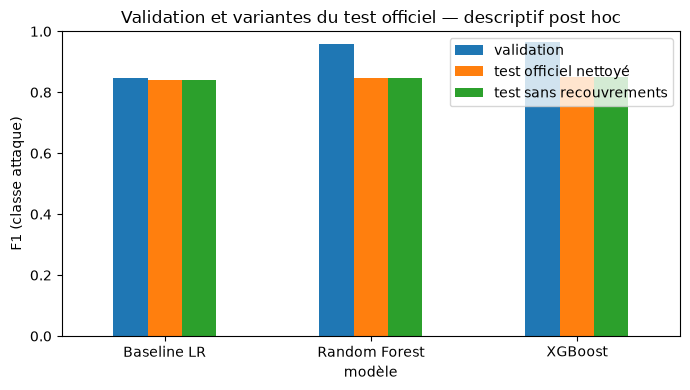

In [17]:
from pathlib import Path
from scipy.stats import ks_2samp

split_summary = pd.DataFrame([
    {"partition": "train", "n": len(y_train), "part attaques": y_train.mean()},
    {"partition": "validation", "n": len(y_val), "part attaques": y_val.mean()},
    {"partition": "test officiel nettoyé", "n": len(y_test_official), "part attaques": y_test_official.mean()},
    {"partition": "test sans recouvrements", "n": len(y_test), "part attaques": y_test.mean()},
]).set_index("partition")
print("Taille et prévalence des attaques :")
display(split_summary.round(3))

family_rates = pd.concat({
    "train": tr.loc[X_train.index, "attack_cat"].value_counts(normalize=True),
    "validation": tr.loc[X_val.index, "attack_cat"].value_counts(normalize=True),
    "test officiel nettoyé": te_official["attack_cat"].value_counts(normalize=True),
    "test sans recouvrements": te["attack_cat"].value_counts(normalize=True),
}, axis=1).fillna(0)
print("Répartition des familles d'attaque (proportions de chaque partition) :")
display(family_rates.round(3))

drift_rows = []
for feature in imp_tab.head(10).index:
    train_values, test_values = X_train[feature], X_test_official[feature]
    if feature in num_cols:
        drift_rows.append({
            "variable": feature,
            "mesure de décalage": "KS D",
            "distance": ks_2samp(train_values, test_values).statistic,
            "médiane train": train_values.median(),
            "médiane test": test_values.median(),
        })
    else:
        train_dist = train_values.value_counts(normalize=True)
        test_dist = test_values.value_counts(normalize=True)
        categories = train_dist.index.union(test_dist.index)
        tv = 0.5 * (train_dist.reindex(categories, fill_value=0) -
                    test_dist.reindex(categories, fill_value=0)).abs().sum()
        drift_rows.append({
            "variable": feature,
            "mesure de décalage": "variation totale",
            "distance": tv,
            "médiane train": "—",
            "médiane test": "—",
        })
drift_table = pd.DataFrame(drift_rows).sort_values("distance", ascending=False)
print("Décalage descriptif des 10 premières variables d'importance (importance calculée sur la validation) :")
display(drift_table.round(3))

f1_comparison = pd.DataFrame({"validation": val_tab.set_index("modèle")["F1 attaque"]})
for partition, rows in [("test officiel nettoyé", test_official_rows),
                        ("test sans recouvrements", test_dedup_rows)]:
    f1_comparison[partition] = pd.DataFrame(rows).set_index("modèle")["F1 attaque"]
Path("figures").mkdir(exist_ok=True)
ax = f1_comparison.plot.bar(figsize=(7, 4), ylim=(0, 1), rot=0)
ax.set_ylabel("F1 (classe attaque)")
ax.set_title("Validation et variantes du test officiel — descriptif post hoc")
plt.tight_layout()
plt.savefig("figures/f1_validation_vs_test.png", dpi=160, bbox_inches="tight")
plt.show()